# Exploratory Data Analysis & Visualization

*Based on: Hyndman & Athanasopoulos, Forecasting: Principles and Practice (3rd ed.), Chapters 2–3*

---


## Learning Objectives

At the end of this notebook, you should be able to:

- Load a time series into pandas with a proper `DatetimeIndex` and a known frequency.
- **Resample** a series to a coarser or finer frequency and choose the right aggregation.
- Read a time-series **line plot** and name the patterns you see (level, trend, seasonality, outliers).
- Build a **seasonal plot** and a **seasonal subseries plot** to inspect seasonality directly.
- Use **lag plots** and the **ACF/PACF** to spot autocorrelation by eye and by number.


## Setup

We use the same scientific-Python stack as notebook 1, plus statsmodels' built-in
plotting helpers for the autocorrelation functions.


In [2]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from statsmodels.datasets import co2, elec_equip, get_rdataset
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# NB_FAST=1 lets CI skip the slow paths. This notebook is cheap so there
# isn't much to skip, but we expose the flag for consistency.
NB_FAST = os.environ.get("NB_FAST", "").lower() in {"1", "true", "yes"}

sns.set_theme(style="whitegrid", context="notebook")


## 2.1 Loading a time series with a real `DatetimeIndex`

Most pandas operations on a series only behave like time-series operations when
the index is a `DatetimeIndex` **and** the frequency is known. We start from
the classic *AirPassengers* dataset and attach a monthly index explicitly.


In [3]:
# Monthly airline passenger counts, 1949-01 .. 1960-12 (144 months).
air_raw = get_rdataset("AirPassengers").data
air = air_raw["value"].copy()
air.index = pd.date_range("1949-01-01", periods=len(air), freq="MS")
air.name = "passengers"

print("dtype :", air.dtype)
print("length:", len(air))
print("index :", air.index[:3].tolist(), "...")
print("freq  :", air.index.freqstr)


dtype : int64
length: 144
index : [Timestamp('1949-01-01 00:00:00'), Timestamp('1949-02-01 00:00:00'), Timestamp('1949-03-01 00:00:00')] ...
freq  : MS


A few quick sanity checks: the series should sort itself by time, have no
missing months, and span the period we expect.


In [4]:
assert air.index.is_monotonic_increasing
assert air.isna().sum() == 0
assert len(air) == 12 * 12  # 12 years × 12 months

air.head()


1949-01-01    112
1949-02-01    118
1949-03-01    132
1949-04-01    129
1949-05-01    121
Freq: MS, Name: passengers, dtype: int64

## 2.2 Resampling: changing the frequency

**Downsampling** moves to a coarser frequency (e.g. monthly → annual).
**Upsampling** moves to a finer frequency (e.g. monthly → daily) and forces
you to decide how to fill in the new timestamps.

The right *aggregation* depends on what the series measures: sum total
passengers per year, but average a temperature reading.


In [5]:
# Downsample: monthly counts -> annual totals (sum) and annual means.
annual_total = air.resample("YE").sum()
annual_mean = air.resample("YE").mean()

annual = pd.concat([annual_total, annual_mean], axis=1, keys=["total", "mean"])
annual.head()


,total,mean
1949-12-31,1520,126.666667
1950-12-31,1676,139.666667
1951-12-31,2042,170.166667
1952-12-31,2364,197.000000
1953-12-31,2700,225.000000


For *upsampling* the question is how to invent values for the new timestamps.
`ffill` carries the previous monthly value forward; `interpolate` draws a
straight line between them. Neither creates new information, they just make
the time axis denser.


In [6]:
# Upsample 12 months around 1955 from monthly to daily, two ways.
window = air.loc["1955"]
upsampled_ffill = window.resample("D").ffill()
upsampled_interp = window.resample("D").interpolate(method="linear")

pd.DataFrame({"ffill": upsampled_ffill, "interp": upsampled_interp}).head()


,ffill,interp
1955-01-01,242,242.000000
1955-01-02,242,241.709677
1955-01-03,242,241.419355
1955-01-04,242,241.129032
1955-01-05,242,240.838710


## 2.3 The line plot: your first diagnostic

The line plot is the single most important EDA tool for a time series. Look
for four things every time:

1. **Level**: where does the series sit on the y-axis?
2. **Trend**: is the level moving up, down, or sideways over time?
3. **Seasonality**: are there regular peaks/troughs at a fixed period?
4. **Outliers and breaks**: any one-off spikes, gaps, or regime shifts?


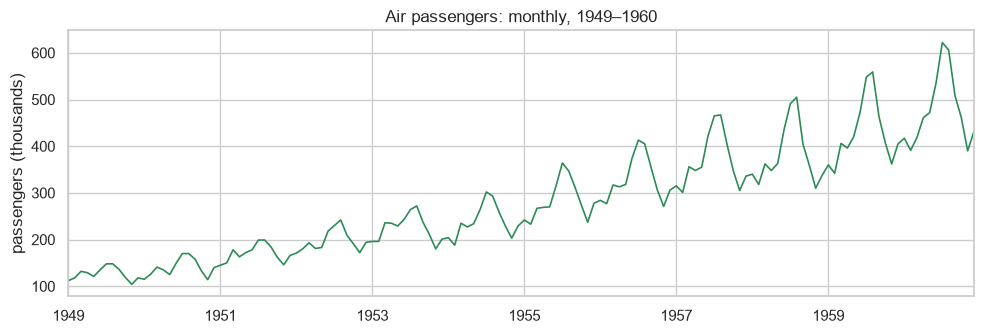

In [7]:
fig, ax = plt.subplots(figsize=(10, 3.5))
air.plot(ax=ax, color="seagreen", linewidth=1.2)
ax.set_title("Air passengers: monthly, 1949–1960")
ax.set_ylabel("passengers (thousands)")
ax.set_xlabel("")
plt.tight_layout()
plt.show()


We will use two more datasets throughout the notebook for variety.
**CO2** at Mauna Loa shows a slow upward trend with strong seasonality;
**Electrical equipment orders** shows a cycle with no obvious yearly period.


In [8]:
# CO2: weekly observations, resampled to monthly mean (1958-03 .. 2001-12).
co2_data = co2.load_pandas().data.resample("MS").mean().squeeze()
co2_data.name = "co2_ppm"

# Electrical equipment orders, monthly (1995-01 .. 2016-05).
equip = elec_equip.load_pandas().data.squeeze()
equip.name = "equip_index"

print("CO2  range:", co2_data.index.min().date(), "..", co2_data.index.max().date())
print("Equip range:", equip.index.min().date(), "..", equip.index.max().date())


CO2  range: 1958-03-01 .. 2001-12-01
Equip range: 1995-01-01 .. 2016-05-01


Plot the two together so the contrast is obvious. CO2 has a textbook
trend-plus-seasonality shape; electrical-equipment orders show a longer,
less regular cycle.


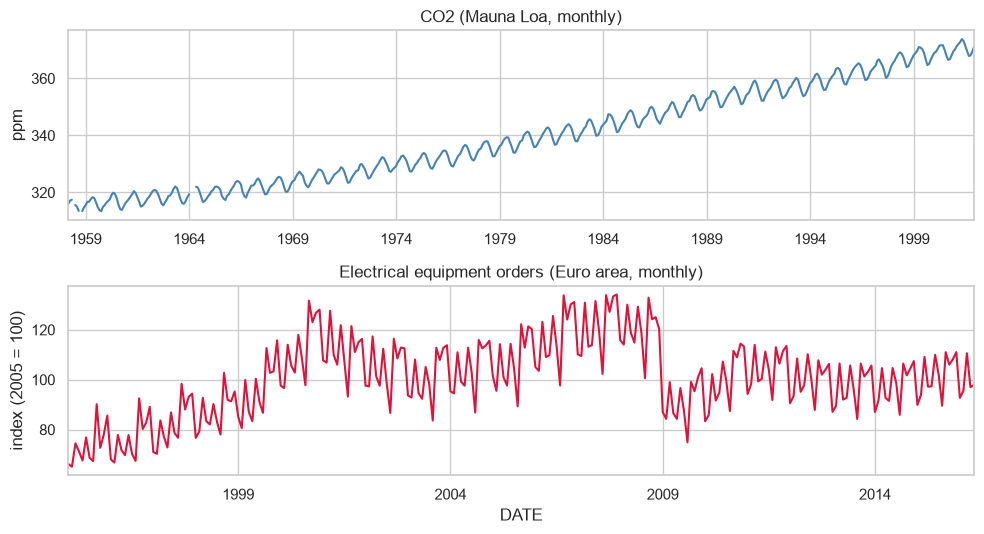

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(10, 5.5), sharex=False)
co2_data.plot(ax=axes[0], color="steelblue")
axes[0].set_title("CO2 (Mauna Loa, monthly)")
axes[0].set_ylabel("ppm")

equip.plot(ax=axes[1], color="crimson")
axes[1].set_title("Electrical equipment orders (Euro area, monthly)")
axes[1].set_ylabel("index (2005 = 100)")

plt.tight_layout()
plt.show()


## 2.4 Seasonal plots: making seasonality obvious

A **seasonal plot** stacks every period of one season on top of each other,
each year becomes its own line, x-axis is month. It exaggerates the seasonal
shape and makes year-on-year *changes* in that shape easy to see.


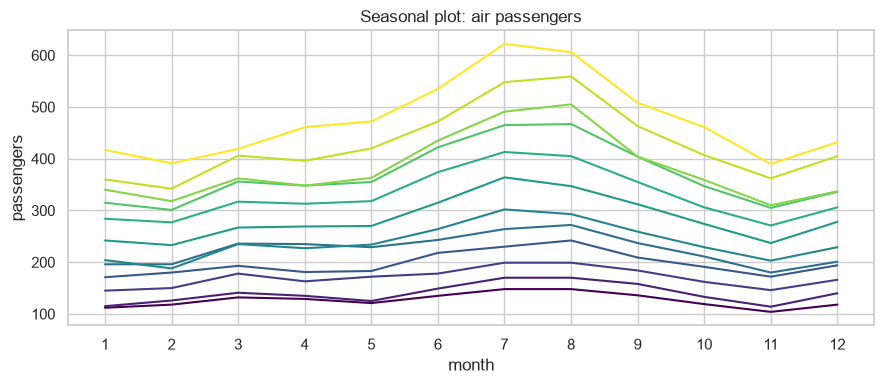

In [10]:
# One line per year, x = month.
air_by_year = air.to_frame("passengers").assign(
    year=air.index.year,
    month=air.index.month,
)

fig, ax = plt.subplots(figsize=(9, 4))
sns.lineplot(
    data=air_by_year, x="month", y="passengers", hue="year",
    palette="viridis", legend=False, ax=ax,
)
ax.set_title("Seasonal plot: air passengers")
ax.set_xticks(range(1, 13))
plt.tight_layout()
plt.show()


The **seasonal subseries plot** groups all observations belonging to the same
season (here: month) into their own little time series. Useful for spotting
months whose behaviour has changed over the years.


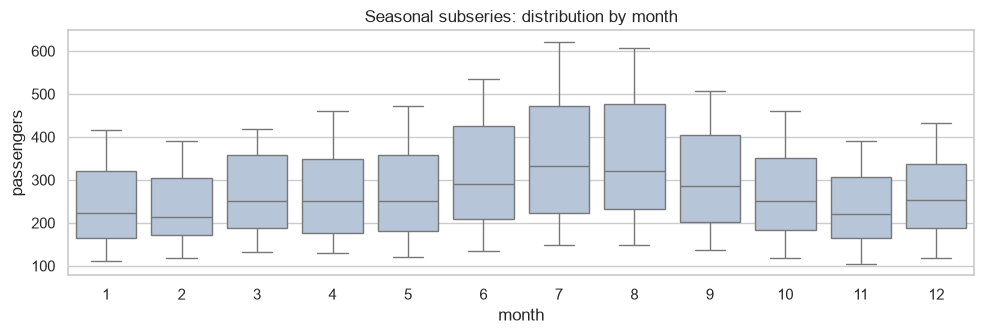

In [11]:
fig, ax = plt.subplots(figsize=(10, 3.5))
sns.boxplot(data=air_by_year, x="month", y="passengers", color="lightsteelblue", ax=ax)
ax.set_title("Seasonal subseries: distribution by month")
plt.tight_layout()
plt.show()


## 2.5 Lag plots: seeing autocorrelation

A **lag plot** is a scatter of $y_t$ against $y_{t-k}$ for a chosen lag $k$.
If points cluster around the diagonal, the series is strongly correlated with
its own past at that lag.


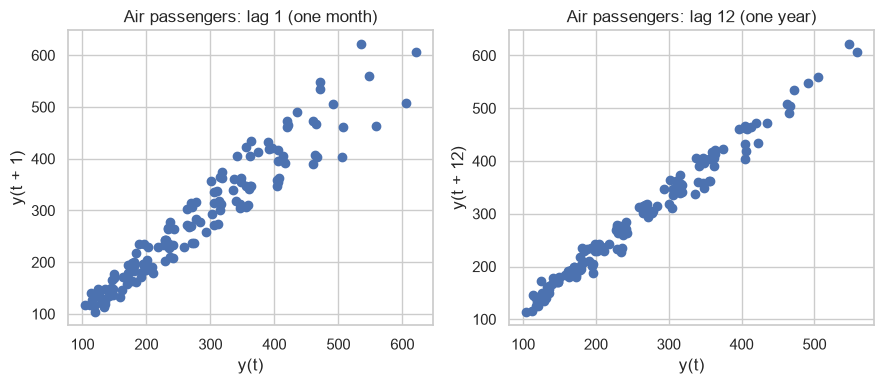

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))

pd.plotting.lag_plot(air, lag=1, ax=axes[0])
axes[0].set_title("Air passengers: lag 1 (one month)")

pd.plotting.lag_plot(air, lag=12, ax=axes[1])
axes[1].set_title("Air passengers: lag 12 (one year)")

plt.tight_layout()
plt.show()


Both lags show clear positive autocorrelation, but the lag-12 pattern is
the *tightest*, confirming that the strongest predictor of this month's
passengers is what happened **one year ago**, not just last month.


## 2.6 ACF and PACF: quantifying autocorrelation

The **autocorrelation function (ACF)** plots correlation against every lag.
The **partial autocorrelation function (PACF)** removes the indirect
contribution of intermediate lags, useful for spotting *direct* dependence.

We will use these systematically when we fit ARIMA models in notebook 4;
for now, treat them as another way to *see* the structure of a series.


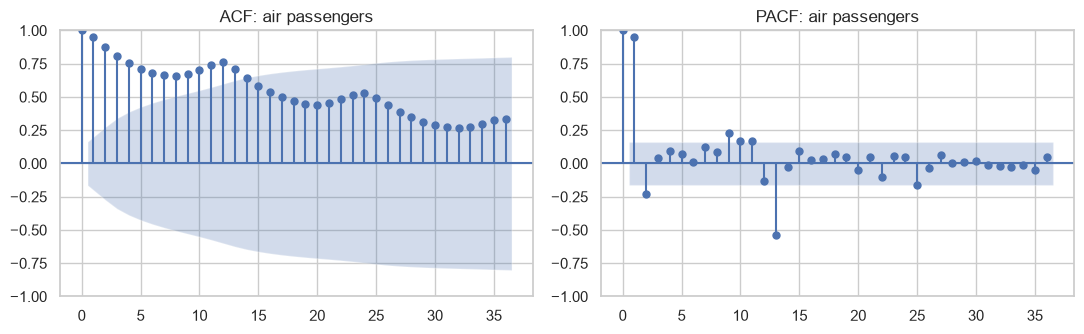

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
plot_acf(air, lags=36, ax=axes[0])
plot_pacf(air, lags=36, ax=axes[1], method="ywm")
axes[0].set_title("ACF: air passengers")
axes[1].set_title("PACF: air passengers")
plt.tight_layout()
plt.show()


Two things to take away from the air-passengers ACF/PACF:

- The ACF stays high for many lags, that is the signature of a strong **trend**.
- Both ACF and PACF show prominent spikes at lag **12**: that is the **seasonal**
  period popping out of the noise.


## Exercises

These exercises reuse the CO2 and electrical-equipment series loaded above.
Make a copy of the relevant cells, swap the dataset, and *look* at the
results, interpretation is the point.

**Exercise 2.1**: *Resample and aggregate.*
Resample `co2_data` to annual frequency two ways: (a) annual mean, (b) annual
maximum. Plot both on the same axes. Which one tells a clearer story about
the long-term trend, and why?

*Hint:* `co2_data.resample("YE").agg(["mean", "max"])`.

**Exercise 2.2**: *Seasonal plot for CO2.*
Build a seasonal plot for `co2_data` (one line per year, x = month). Does
CO2 show a regular seasonal cycle? If yes, which month tends to be highest
and why might that be?

**Exercise 2.3**: *Compare ACFs.*
Plot the ACF of `equip` (electrical equipment) for 60 lags. Compared to the
air-passengers ACF, does it look more like a series dominated by trend, by
seasonality, by cycle, or by noise? Write two sentences describing what you
see.

**Exercise 2.4 (stretch)**: *Diagnose a series from scratch.*
Load the `nile` dataset with
`get_rdataset("Nile").data` (annual flow of the Nile, 1871–1970) and run
the same four diagnostics: line plot, seasonal plot (if meaningful), lag
plot, ACF. Write three sentences about what you found.


In [14]:
annual = co2_data.resample("YE").agg(["mean", "max"])
annual.head()

,mean,max
1958-12-31,315.366667,317.433333
1959-12-31,316.000694,318.325000
1960-12-31,316.875000,319.925000
1961-12-31,317.605000,320.475000
1962-12-31,318.412917,320.900000


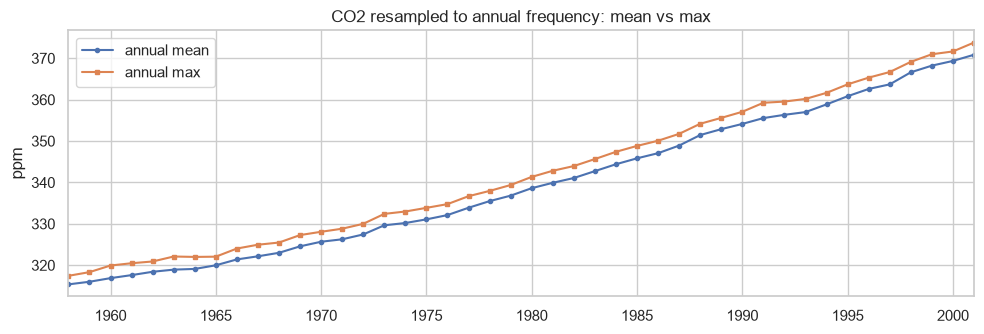

In [16]:
annual = co2_data.resample("YE").agg(["mean", "max"])

fig, ax = plt.subplots(figsize=(10, 3.5))
annual["mean"].plot(ax=ax, marker="o", markersize=3, label="annual mean")
annual["max"].plot(ax=ax, marker="s", markersize=3, label="annual max")
ax.set_title("CO2 resampled to annual frequency: mean vs max")
ax.set_ylabel("ppm")
ax.legend()
plt.tight_layout()
plt.show()

**Exercise 2.1: annual mean vs annual max**

Both lines rise in parallel at about 1.3 ppm per year, so both show the long-term trend. The **annual mean** tells the clearer story: averaging a full year covers one complete seasonal cycle, so the seasonal effect cancels out and only the trend remains. The **annual max** is trend plus each year's May peak, and it depends on a single month, so it carries extra noise: its year-to-year changes are about 16% more uneven (std 0.65 vs 0.56 ppm) and the gap between the two lines varies from 2.1 to 3.7 ppm. Note that 1958 is a partial year (data starts in March and two months are missing), so its annual mean is based on only 8 months.

---

*Hyndman, R.J. & Athanasopoulos, G. (2021), Forecasting: Principles and
Practice (3rd ed.), Chapters 2 (graphics) and 3 (decomposition / lag
relationships). <https://otexts.com/fpp3/>*
